<a href="https://colab.research.google.com/github/peeyush211/ML-Lab/blob/main/Decision_Tree_Lab_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lab 5**

**Aim - Using a samplte dataest perform Decision Tree using using cart id3 c45 ACCURACY AND  compare F measure ,recall for each algorithm**

**Name- Peeyush Agarwal 2427010184 AIM3130**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
df = pd.read_csv("riceClassification.csv")

In [ ]:
# Check the number of records, attributes, data types and missing values
df.head()
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18185 entries, 0 to 18184
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               18185 non-null  int64  
 1   Area             18185 non-null  int64  
 2   MajorAxisLength  18185 non-null  float64
 3   MinorAxisLength  18185 non-null  float64
 4   Eccentricity     18185 non-null  float64
 5   ConvexArea       18185 non-null  int64  
 6   EquivDiameter    18185 non-null  float64
 7   Extent           18185 non-null  float64
 8   Perimeter        18185 non-null  float64
 9   Roundness        18185 non-null  float64
 10  AspectRation     18185 non-null  float64
 11  Class            18185 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 1.7 MB


In [ ]:
df.columns

Index(['id', 'Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity',
       'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness',
       'AspectRation', 'Class'],
      dtype='object')

In [ ]:
df['Class'].value_counts()  # Check the distribution of different rice classes in the target column

,count
Class,
1,9985
0,8200


In [ ]:
#Predict y as a target feature and x includes all other attributes as feature and drops id and Class
x = df.drop(['id','Class'], axis=1)
y = df['Class']

In [ ]:
# Split the dataset into 80% training data and 20% testing data
# stratify=y keeps the class distribution similar in both sets
x_train ,x_test , y_train , y_test = train_test_split(x , y , test_size= 0.2 , random_state=42 , stratify=y)

In [ ]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (14548, 10)
Testing data: (3637, 10)


In [ ]:
# CART uses Gini Impurity as the splitting criterion
# Train the CART model using the training data
cart = DecisionTreeClassifier( criterion='gini', random_state=42 )
cart.fit(x_train, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
# Predict the classes of the unseen test data
y_pred_cart = cart.predict(x_test)

In [ ]:
# Calculate Accuracy, Precision, Recall and F-Measure for CART
# Weighted averaging is used because this is a multiclass classification problem
cart_accuracy = accuracy_score(y_test, y_pred_cart)
cart_precision = precision_score(y_test, y_pred_cart, average='weighted')
cart_recall = recall_score(y_test, y_pred_cart, average='weighted')
cart_f1 = f1_score(y_test, y_pred_cart, average='weighted')
print("CART Accuracy :", cart_accuracy)
print("CART Precision:", cart_precision)
print("CART Recall   :", cart_recall)
print("CART F-Measure:", cart_f1)

CART Accuracy : 0.9843277426450371
CART Precision: 0.9843316348583468
CART Recall   : 0.9843277426450371
CART F-Measure: 0.9843290129367384


In [ ]:
# ID3 uses Entropy (Information Gain) for selecting the best split
# Train the ID3-style decision tree
id3 = DecisionTreeClassifier(criterion='entropy', random_state=42)
id3.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [ ]:
y_pred_id3 = id3.predict(x_test)

In [ ]:
accuracy_score(y_test, y_pred_id3)

0.9851525982952983

In [ ]:
# Calculate Accuracy, Precision, Recall and F-Measure for ID3
id3_accuracy = accuracy_score(y_test, y_pred_id3)
id3_precision = precision_score(y_test, y_pred_id3, average='weighted')
id3_recall = recall_score(y_test, y_pred_id3, average='weighted')
id3_f1 = f1_score(y_test, y_pred_id3, average='weighted')

print("ID3 Accuracy :", id3_accuracy)
print("ID3 Precision:", id3_precision)
print("ID3 Recall   :", id3_recall)
print("ID3 F-Measure:", id3_f1)

ID3 Accuracy : 0.9851525982952983
ID3 Precision: 0.9851525982952983
ID3 Recall   : 0.9851525982952983
ID3 F-Measure: 0.9851525982952983


In [ ]:
!pip install chefboost

In [ ]:
# Chefboost requires the target column to be included in the training DataFrame
# Remove the ID column and keep Class as the target
c45_df = df.drop('id', axis=1).copy()
c45_df = c45_df[
    ['Area', 'MajorAxisLength', 'MinorAxisLength','Eccentricity', 'ConvexArea', 'EquivDiameter','Extent', 'Perimeter', 'Roundness', 'AspectRation', 'Class']]
c45_df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


In [ ]:
# Configure Chefboost to use the C4.5 algorithm
# C4.5 selects splits using Gain Ratio
from chefboost import Chefboost as chef
config = {'algorithm': 'C4.5'}
model_c45 = chef.fit(c45_df,config=config,target_label='Class')

26-09-08 15:23:18 - ⚠️ You set the algorithm to C4.5 but the Decision column of your data set has non-object type.That's why, the algorithm is set to Regression to handle the data set.
26-09-08 15:23:18 - Regression tree is going to be built...
26-09-08 15:23:35 - -------------------------
26-09-08 15:23:35 - finished in 17.264566898345947 seconds
26-09-08 15:23:45 - -------------------------
26-09-08 15:23:45 - Evaluate train set
26-09-08 15:23:45 - -------------------------
26-09-08 15:23:45 - MAE: 0.019080584315474124
26-09-08 15:23:45 - MSE: 0.009540292157737053
26-09-08 15:23:45 - RMSE: 0.09767441915740811
26-09-08 15:23:45 - RAE: 0.13181458157092069
26-09-08 15:23:45 - RRSE 0.19629678283123622
26-09-08 15:23:45 - Mean: 0.5490789111905416
26-09-08 15:23:45 - MAE / Mean: 3.4750167829433845%
26-09-08 15:23:45 - RMSE / Mean: 17.788776288206975%


In [ ]:
c45_train = x_train.copy()
c45_train['Class'] = y_train.values
c45_test = x_test.copy()
c45_test['Class'] = y_test.values

In [ ]:
config = {'algorithm': 'C4.5'}
model_c45 = chef.fit(c45_train,config=config,target_label='Class')

26-09-08 15:23:46 - ⚠️ You set the algorithm to C4.5 but the Decision column of your data set has non-object type.That's why, the algorithm is set to Regression to handle the data set.
26-09-08 15:23:46 - Regression tree is going to be built...
26-09-08 15:23:58 - -------------------------
26-09-08 15:23:58 - finished in 12.9158296585083 seconds
26-09-08 15:24:08 - -------------------------
26-09-08 15:24:08 - Evaluate train set
26-09-08 15:24:08 - -------------------------
26-09-08 15:24:08 - MAE: 0.019390071138904216
26-09-08 15:24:08 - MSE: 0.009695035569452108
26-09-08 15:24:08 - RMSE: 0.09846337171482657
26-09-08 15:24:08 - RAE: 0.1328792968989722
26-09-08 15:24:08 - RRSE 0.1978823448459756
26-09-08 15:24:08 - Mean: 0.5490789111905416
26-09-08 15:24:08 - MAE / Mean: 3.5313815088730416%
26-09-08 15:24:08 - RMSE / Mean: 17.932462840602117%


In [ ]:
# Configure Chefboost to use the C4.5 algorithm
# C4.5 selects splits using Gain Ratio
y_pred_c45 = []
for _, row in x_test.iterrows():prediction = chef.predict(model_c45,row.values.tolist())
y_pred_c45.append(prediction)

In [ ]:
# Calculate Accuracy, Precision, Recall and F-Measure for C4.5
y_pred_c45_binary = [1 if p >= 0.5 else 0 for p in y_pred_c45]
c45_accuracy = accuracy_score(y_test, y_pred_c45_binary)
c45_precision = precision_score(y_test, y_pred_c45_binary, average='weighted')
c45_recall = recall_score(y_test, y_pred_c45_binary, average='weighted')
c45_f1 = f1_score(y_test, y_pred_c45_binary, average='weighted')
print("C4.5 Accuracy :", c45_accuracy)
print("C4.5 Precision:", c45_precision)
print("C4.5 Recall   :", c45_recall)
print("C4.5 F-Measure:", c45_f1)

C4.5 Accuracy : 0.9873522133626615
C4.5 Precision: 0.9873534351835997
C4.5 Recall   : 0.9873522133626615
C4.5 F-Measure: 0.987350109905171


In [ ]:
# Generate confusion matrices to compare actual and predicted classes
# Rows represent actual classes and columns represent predicted classes
from sklearn.metrics import confusion_matrix
cm_cart = confusion_matrix(y_test, y_pred_cart)
print("CART Confusion Matrix:")
print(cm_cart)

CART Confusion Matrix:
[[1613   27]
 [  30 1967]]


In [ ]:
cm_id3 = confusion_matrix(y_test, y_pred_id3)
print("ID3 Confusion Matrix:")
print(cm_id3)

ID3 Confusion Matrix:
[[1613   27]
 [  27 1970]]


In [ ]:
cm_c45 = confusion_matrix(y_test, y_pred_c45_binary)
print("C4.5 Confusion Matrix:")
print(cm_c45)

C4.5 Confusion Matrix:
[[1614   26]
 [  20 1977]]


In [ ]:
# Create a comparison table for all three Decision Tree algorithms
# Compare Accuracy, Precision, Recall and F-Measure
comparison = pd.DataFrame({
    'Algorithm': ['CART', 'ID3', 'C4.5'],
    'Accuracy': [cart_accuracy, id3_accuracy, c45_accuracy],
    'Precision': [cart_precision, id3_precision, c45_precision],
    'Recall': [cart_recall, id3_recall, c45_recall],
    'F-Measure': [cart_f1, id3_f1, c45_f1]
})

comparison

,Algorithm,Accuracy,Precision,Recall,F-Measure
0,CART,0.984328,0.984332,0.984328,0.984329
1,ID3,0.985153,0.985153,0.985153,0.985153
2,C4.5,0.987352,0.987353,0.987352,0.987350


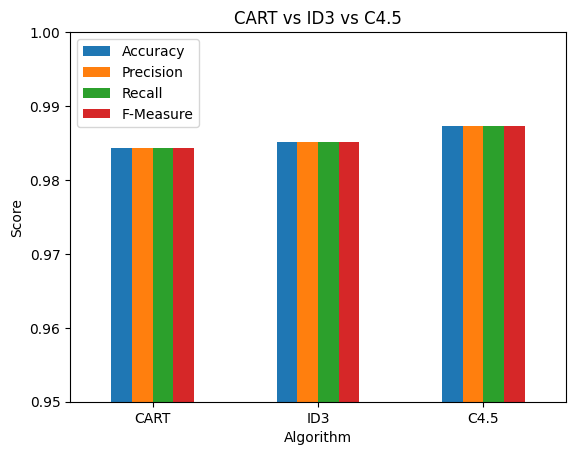

In [ ]:
# Visualize the performance of CART, ID3 and C4.5 using a bar graph
comparison.set_index('Algorithm').plot(kind='bar')
plt.title('CART vs ID3 vs C4.5')
plt.ylabel('Score')
plt.xlabel('Algorithm')
plt.ylim(0.95, 1.0)
plt.xticks(rotation=0)
plt.legend()
plt.show()